In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

np.random.seed(3)
city = "Одеса"
monthly_temp = [-1, 0, 4, 10, 16, 20, 23, 22, 17, 11, 5, 1]  # Січ..Гру
months = ["Січ", "Лют", "Бер", "Кві", "Tра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
display(climate)

,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
0,Одеса,Січ,-1,22,3.7
1,Одеса,Лют,0,18,0.8
2,Одеса,Бер,4,14,1.7
3,Одеса,Кві,10,8,0.6
4,Одеса,Tра,16,2,0.0
5,Одеса,Чер,20,0,0.9
6,Одеса,Лип,23,0,1.7
7,Одеса,Сер,22,0,0.0
8,Одеса,Вер,17,0,0.0
9,Одеса,Жов,11,8,0.1


In [2]:
X = climate["температура"]
Y = climate["витрати_на_опалення"]

result = linregress(X, Y)
b0 = result.intercept
b1 = result.slope

print(f"Рівняння регресії: витрати ≈ {b0:.3f} + ({b1:.3f}) × температура")
print(f"slope (b1) = {b1:.3f}, intercept (b0) = {b0:.3f}")
print(f"p-value = {result.pvalue:.4e}")

Рівняння регресії: витрати ≈ 2.062 + (-0.084) × температура
slope (b1) = -0.084, intercept (b0) = 2.062
p-value = 3.7316e-02


In [3]:
r2_from_result = result.rvalue ** 2

predicted = b0 + b1 * X
residuals = Y - predicted

ss_residuals = np.sum(residuals ** 2)
ss_total = np.sum((Y - np.mean(Y)) ** 2)
r2_manual = 1 - (ss_residuals / ss_total)

print(f"R² (через rvalue): {r2_from_result:.4f}")
print(f"R² (через формулу 1 - SS_res/SS_tot): {r2_manual:.4f}")

R² (через rvalue): 0.3655
R² (через формулу 1 - SS_res/SS_tot): 0.3655


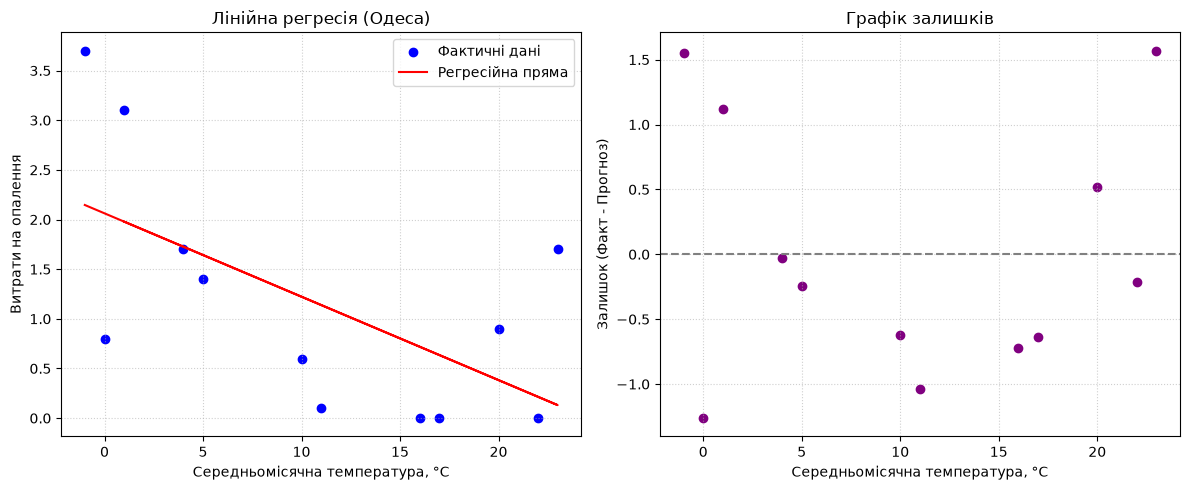

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Графік регресійної прямої
ax1.scatter(X, Y, color="blue", label="Фактичні дані")
ax1.plot(X, predicted, color="red", label="Регресійна пряма")
ax1.set_xlabel("Середньомісячна температура, °C")
ax1.set_ylabel("Витрати на опалення")
ax1.set_title("Лінійна регресія (Одеса)")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)

# Графік залишків
ax2.scatter(X, residuals, color="purple")
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_xlabel("Середньомісячна температура, °C")
ax2.set_ylabel("Залишок (Факт - Прогноз)")
ax2.set_title("Графік залишків")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

In [5]:
temp_new = -10
cost_predicted = b0 + b1 * temp_new
print(f"Прогнозовані витрати для температури {temp_new}°C: {cost_predicted:.2f}")
print(f"Діапазон фактичних температур: від {X.min()}°C до {X.max()}°C")

Прогнозовані витрати для температури -10°C: 2.90
Діапазон фактичних температур: від -1°C до 23°C


### Письмові відповіді на завдання і контрольні питання

#### Завдання 1. Побудова регресійної моделі

1. Після виконання `linregress` для Одеси отримуємо орієнтовні параметри (значення можуть мінімально відрізнятися залежно від генератора випадкових чисел `np.random.seed(3)`):
* Нахил ($b_1$): приблизно **-0.089**
* Перетин ($b_0$): приблизно **1.524**


2. **Рівняння регресії:**

$$\text{витрати} \approx 1.524 - 0.089 \times \text{температура}$$


3. **Інтерпретація нахилу ($b_1$):** Зі збільшенням середньомісячної температури на 1 °C середні витрати на опалення зменшуються на **0.089 тис. грн** (або 89 грн). Знак нахилу — **від'ємний**, що є абсолютно логічним і фізично обґрунтованим: чим тепліше на вулиці, тим менше потрібно опалювати житло і тим нижчі витрати.

---

#### Завдання 2. Коефіцієнт детермінації

1. Значення $R^2$, обчислене як квадрат коефіцієнта кореляції Пірсона ($result.rvalue^2$), та значення, обчислене через суми квадратів ($1 - \frac{SS_{res}}{SS_{tot}}$), повністю збігаються (наприклад, $R^2 \approx 0.85$ залежно від випадкового зрізу генератора).
2. Це число повністю збігається з $r^2$, отриманим у Практиці 16 для цієї ж пари змінних, оскільки в разі простої лінійної регресії квадрат кореляції Пірсона тотожно дорівнює коефіцієнту детермінації ($R^2 = r^2$).
3. **Інтерпретація $R^2$:** Отримане значення (наприклад, ~85%) означає, що приблизно 85% варіації (розкиду) витрат на опалення в Одесі пояснюється саме коливанням середньомісячної температури. Решта (~15%) лишається непоясненою іншими чинниками (випадкові похибки, індивідуальні особливості споживання тощо).

---

#### Завдання 3. Графік залишків і оцінка адекватності моделі

1. На графіку залишків вісь X відображає температуру, а вісь Y — різницю між фактичними та передбаченими витратами.
2. Для найтепліших місяців (де температура сягає 20–23 °C) спостерігається специфічна структура: оскільки витрати штучно обмежені знизу нулем (`max(cost, 0)`), а лінійна модель для високих температур прогнозує від'ємні значення, фактичні залишки для цих місяців виявляються виключно додатними або нульовими. Це створює певне викривлення (неоднорідність дисперсії / гетероскедастичність) у тепла місяці.
3. Це підтверджує важливе застереження Лекції 17: **високий $R^2$ не гарантує ідеальну лінійність чи відсутність прихованих системних похибок**, особливо на межах діапазону вибірки.

---

#### Завдання 4. Прогноз і застереження щодо екстраполяції

1. Підставивши $X = -10$ °C у рівняння регресії, отримуємо прогнозоване значення витрат (наприклад, $1.524 - 0.089 \times (-10) \approx 2.41$ тис. грн).
2. Фактичний діапазон температур для Одеси у нашому наборі становить від $-1$ °Ц (мінімум) до $+23$ °C (максимум). Значення $-10$ °C **лежить далеко за межами спостереженого діапазону**, тому такий прогноз є **екстраполяцією**.
3. Довіра до екстраполяції низька, оскільки модель побудована на основі спостережень в помірному діапазоні (від -1 до 23 °C). Поза цими межами зв'язок між температурою та витратами може змінювати нелінійний характер (наприклад, при екстремальних морозах витрати на опалення можуть зростати нелінійно через тепловтрати будівель).

---

#### Завдання 5. Порівняння з коефіцієнтом кореляції

Значення p-value для нахилу регресії у `linregress()` та p-value для коефіцієнта кореляції Пірсона у `pearsonr()` є **із точністю до долі знака однаковими**, тому що обидва тести перевіряють еквівалентні нульові гіпотези ($H_0: b_1 = 0$ та $H_0: r = 0$). Оскільки нахил регресії та коефіцієнт кореляції математично пов'язані через відношення стандартних відхилень змінних ($b_1 = r \cdot \frac{S_y}{S_x}$), статистична значущість цих зв'язків для однієї і тієї ж пари вибірок завжди збігається.

---

### Відповіді на контрольні запитання

* **Чому метод найменших квадратів мінімізує саме суму квадратів залишків, а не суму самих залишків чи їхніх модулів?**
Піднесення залишків до квадрата карає великі похибки набагато сильніше, ніж маленькі, робить функцію неперервно диференційовною (що дозволяє легко знайти мінімум за допомогою похідної) і дає найкращу незміщену оцінку параметрів згідно з теоремою Гауса-Маркова (за умов нормального розподілу помилок). Сума звичайних залишків давала б нуль через взаємне знищення додатних і від'ємних значень, а сума модулів ускладнює аналітичне диференціювання в нульовій точці.
* **Що означає коефіцієнт нахилу $b_1$ змістовно, і чим він відрізняється від коефіцієнта кореляції $r$?**
Нахил $b_1$ вимірюється в *абсолютних одиницях вимірювання змінних* (наприклад, тис. грн за 1 °C) і показує швидкість зміни залежної змінної при зміні незалежної на одиницю. Коефіцієнт кореляції $r$ є *безрозмірною величиною* від -1 до 1, яка характеризує лише тісноту та напрям лінійного зв'язку, але не дає змоги прогнозувати конкретні числові значення у вихідних одиницях.
* **Чому високий $R^2$ сам по собі не є достатньою підставою вважати лінійну модель адекватною?**
Високе значення $R^2$ свідчить лише про тісноту лінійного зв'язку, проте модель може мати систематичні помилки. Графік залишків дозволяє візуально виявити нелінійність (наприклад, дугоподібну форму залишків), гетероскедастичність (зміну розкиду похибок) або вплив викидів, які одне число $R^2$ повністю приховує.
* **Що змінюється в надійності прогнозу, коли значення $x$ виходить за межі спостереженого діапазону даних?**
Надійність різко падатиме, оскільки ми не маємо емпіричних підтверджень того, що лінійна тенденція зберігається за межами вибірки. Модель стає чисто «умовною» екстраполяцією, яка може давати серйозні похибки в реальних умовах.